# E8: CRNN | 128 Mel bins | có SpecAugment
Nhánh GitHub: `11-E8-crnn-mel128-specaug`

Learning rate chọn trên fold 1 (chỉ dùng validation), sau đó chạy 5 fold (3 train, 1 validation, 1 test) và kiểm tra nhiễu Gaussian SNR 20/10/0 dB. Chạy lại ô sẽ tiếp tục từ fold còn dở.

In [2]:
!pip -q install soundfile
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ESC50')
from esc_lib import *
setup()

Mounted at /content/drive
GPU: Tesla T4 | VRAM 15.6 GB | torch 2.14.1+cu130 | CUDA 13.0
RAM trống 11.8 GB | ổ đĩa trống 120.8 GB
Mixup: BẬT | quick: False | kết quả lưu ở: /content/drive/MyDrive/ESC50/results_mixup


In [3]:
EXP_ID = "E8"
print(EXPERIMENTS[EXP_ID])
meta, X, X_DEV, y, folds = load_data()

{'model': 'crnn', 'n_mels': 128, 'specaug': True}


  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,) | nằm trên: cuda:0


## Tìm learning rate (fold 1)

In [4]:
lr = search_lr(EXP_ID)

E8: đã có learning rate được chọn = 0.001


## Chạy 5 fold và kiểm tra độ bền với nhiễu

In [5]:
runs, rob = run_exp(EXP_ID, lr)

E8 | fold 3:   0%|          | 0/80 [00:00<?, ?it/s]

[E8 | fold 3] acc 0.7600 | macro-F1 0.7539 | lr 0.001 | epoch tốt nhất 75 | 209s


E8 | fold 4:   0%|          | 0/80 [00:00<?, ?it/s]

[E8 | fold 4] acc 0.8400 | macro-F1 0.8384 | lr 0.001 | epoch tốt nhất 61 | 200s


E8 | fold 5:   0%|          | 0/80 [00:00<?, ?it/s]

[E8 | fold 5] acc 0.7450 | macro-F1 0.7309 | lr 0.001 | epoch tốt nhất 61 | 200s


## Kết quả

,fold,acc,macro_f1,lr,best_epoch,val_f1,train_time
0,1,0.760,0.7466,0.001,77,0.8171,202.2245
1,2,0.800,0.7917,0.001,68,0.8049,202.3049
2,3,0.760,0.7539,0.001,75,0.8277,208.6483
3,4,0.840,0.8384,0.001,61,0.7420,199.8318
4,5,0.745,0.7309,0.001,61,0.7914,200.2107


E8: Accuracy 78.10 ± 3.88 | Macro-F1 77.23 ± 4.32 | 2,858,194 tham số


,acc,macro_f1
condition,,
Sạch,78.10,77.23
20 dB,65.00,63.58
10 dB,37.45,38.01
0 dB,7.60,6.52


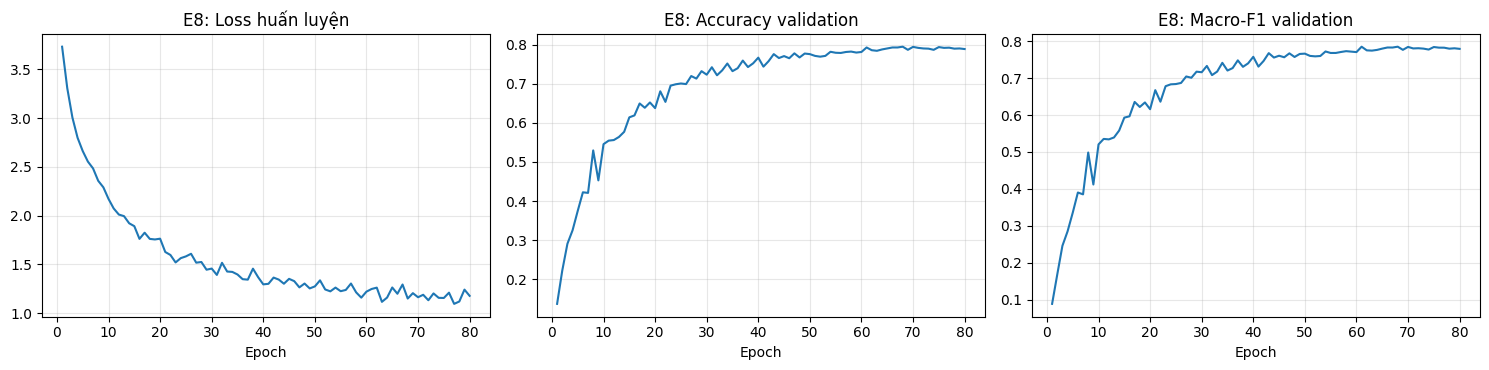

In [6]:
show_exp(EXP_ID)